# Parte Específica: Documentação das Variáveis Derivadas — BankChurners

Dataset: BankChurners, arquivo tratado `out/parte_especifica/bankchurners_tratado.csv`.

Este notebook documenta e verifica empiricamente as duas variáveis derivadas identificadas na EDA relacional (`eda_relacional.ipynb`):
- **`Avg_Open_To_Buy`** (limite de crédito disponível em aberto)
- **`Avg_Utilization_Ratio`** (taxa média de utilização do limite de crédito)

O objetivo é comprovar as fórmulas exatas a partir das variáveis originais (`Credit_Limit` e `Total_Revolving_Bal`), medir eventuais diferenças de arredondamento e registrar as implicações para visualização e modelagem.

In [ ]:
# [IA] Claude Code – verificacao das variaveis derivadas: importacao das bibliotecas e leitura dos dados
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

PASTA_SAIDA = Path("../../out/parte_especifica")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

CAMINHO_TRATADO = PASTA_SAIDA / "bankchurners_tratado.csv"
CAMINHO_BRUTO = Path("../../data/parte_especifica/BankChurners.csv")
CAMINHO_DADOS = CAMINHO_TRATADO if CAMINHO_TRATADO.exists() else CAMINHO_BRUTO

df = pd.read_csv(CAMINHO_DADOS)
if pd.api.types.is_numeric_dtype(df["Attrition_Flag"]):
    df["cancelou"] = df["Attrition_Flag"].astype(int)
else:
    df["cancelou"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)

colunas_chave = ["Credit_Limit", "Total_Revolving_Bal", "Avg_Open_To_Buy", "Avg_Utilization_Ratio"]
print(f"Arquivo: {CAMINHO_DADOS.name} | Linhas: {len(df)}")
df[colunas_chave].describe().T[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(3)

Arquivo: bankchurners_tratado.csv | Linhas: 10127


,min,25%,50%,75%,max,mean,std
Credit_Limit,1438.3,2555.000,4549.000,11067.500,34516.000,8631.954,9088.777
Total_Revolving_Bal,0.0,359.000,1276.000,1784.000,2517.000,1162.814,814.987
Avg_Open_To_Buy,3.0,1324.500,3474.000,9859.000,34516.000,7469.140,9090.685
Avg_Utilization_Ratio,0.0,0.023,0.176,0.503,0.999,0.275,0.276


## 1. Verificação empírica das fórmulas

Testamos duas identidades matemáticas em todos os registros da base:
1. $\text{Avg\_Open\_To\_Buy} = \text{Credit\_Limit} - \text{Total\_Revolving\_Bal}$
2. $\text{Avg\_Utilization\_Ratio} = \dfrac{\text{Total\_Revolving\_Bal}}{\text{Credit\_Limit}}$

In [ ]:
# [IA] Claude Code – verificacao das variaveis derivadas: calculo de correlacoes
calc_open_to_buy = df["Credit_Limit"] - df["Total_Revolving_Bal"]
erro_open = (df["Avg_Open_To_Buy"] - calc_open_to_buy).abs()

calc_util = df["Total_Revolving_Bal"] / df["Credit_Limit"]
erro_util = (df["Avg_Utilization_Ratio"] - calc_util).abs()

verificacao = pd.DataFrame([
    {
        "variavel_derivada": "Avg_Open_To_Buy",
        "formula_testada": "Credit_Limit - Total_Revolving_Bal",
        "erro_medio_abs": round(erro_open.mean(), 6),
        "erro_max_abs": round(erro_open.max(), 6),
        "pct_exato_tolerancia": round((erro_open <= 0.1).mean() * 100, 2),
        "corr_com_formula": round(df["Avg_Open_To_Buy"].corr(calc_open_to_buy), 6),
        "corr_com_cancelou": round(df["Avg_Open_To_Buy"].corr(df["cancelou"]), 4),
    },
    {
        "variavel_derivada": "Avg_Utilization_Ratio",
        "formula_testada": "Total_Revolving_Bal / Credit_Limit",
        "erro_medio_abs": round(erro_util.mean(), 6),
        "erro_max_abs": round(erro_util.max(), 6),
        "pct_exato_tolerancia": round((erro_util <= 0.001).mean() * 100, 2),
        "corr_com_formula": round(df["Avg_Utilization_Ratio"].corr(calc_util), 6),
        "corr_com_cancelou": round(df["Avg_Utilization_Ratio"].corr(df["cancelou"]), 4),
    },
]).set_index("variavel_derivada")

display(verificacao)

# Matriz de correlacao entre as variaveis originais, derivadas e o alvo
cols_corr = ["Credit_Limit", "Total_Revolving_Bal", "Avg_Open_To_Buy", "Avg_Utilization_Ratio", "cancelou"]
print("\nCorrelacao de Pearson entre originais, derivadas e cancelamento:")
display(df[cols_corr].corr(method="pearson").round(4))

,formula_testada,erro_medio_abs,erro_max_abs,pct_exato_tolerancia,corr_com_formula,corr_com_cancelou
variavel_derivada,,,,,,
Avg_Open_To_Buy,Credit_Limit - Total_Revolving_Bal,0.000000,0.0000,100.0,1.0,-0.0003
Avg_Utilization_Ratio,Total_Revolving_Bal / Credit_Limit,0.000188,0.0005,100.0,1.0,-0.1784



Correlacao de Pearson entre originais, derivadas e cancelamento:


,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Avg_Utilization_Ratio,cancelou
Credit_Limit,1.0000,0.0425,0.9960,-0.4830,-0.0239
Total_Revolving_Bal,0.0425,1.0000,-0.0472,0.6240,-0.2631
Avg_Open_To_Buy,0.9960,-0.0472,1.0000,-0.5388,-0.0003
Avg_Utilization_Ratio,-0.4830,0.6240,-0.5388,1.0000,-0.1784
cancelou,-0.0239,-0.2631,-0.0003,-0.1784,1.0000


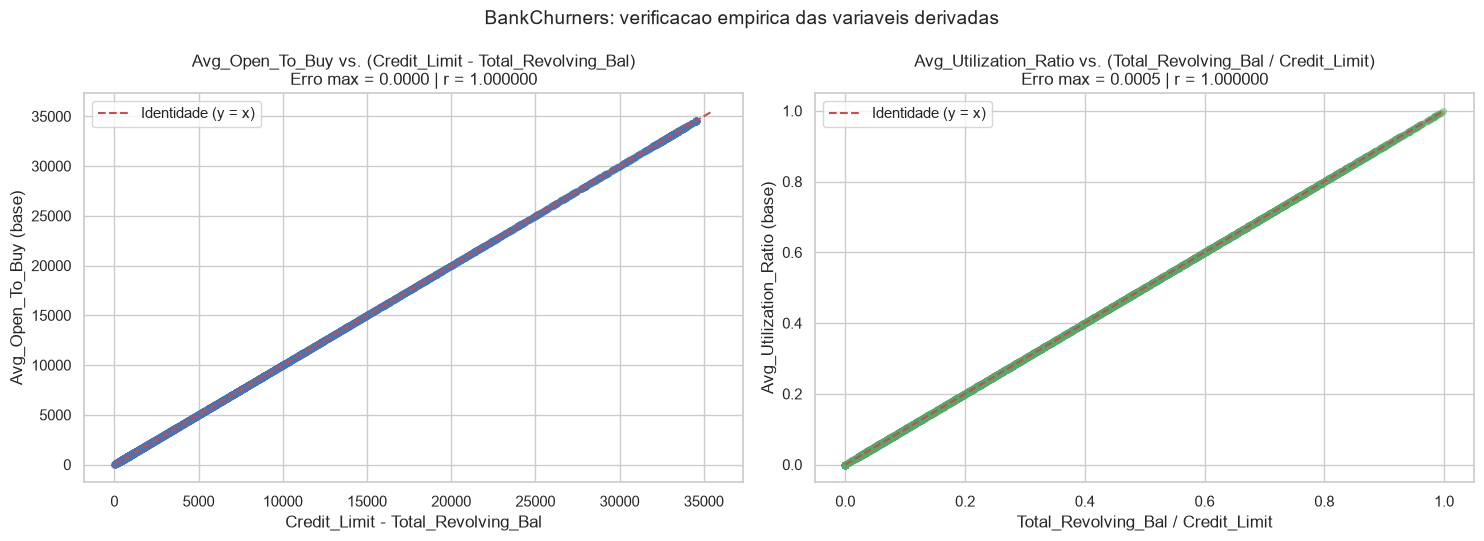

In [ ]:
# [IA] Claude Code – verificacao das variaveis derivadas: grafico
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Avg_Open_To_Buy
axes[0].scatter(calc_open_to_buy, df["Avg_Open_To_Buy"], alpha=0.35, s=18, color="#4C72B0")
lim0 = [0, max(calc_open_to_buy.max(), df["Avg_Open_To_Buy"].max()) * 1.03]
axes[0].plot(lim0, lim0, "--", color="#C44E52", linewidth=1.5, label="Identidade (y = x)")
axes[0].set_title(f"Avg_Open_To_Buy vs. (Credit_Limit - Total_Revolving_Bal)\nErro max = {erro_open.max():.4f} | r = {df['Avg_Open_To_Buy'].corr(calc_open_to_buy):.6f}")
axes[0].set_xlabel("Credit_Limit - Total_Revolving_Bal")
axes[0].set_ylabel("Avg_Open_To_Buy (base)")
axes[0].legend()

# 2. Avg_Utilization_Ratio
axes[1].scatter(calc_util, df["Avg_Utilization_Ratio"], alpha=0.35, s=18, color="#55A868")
axes[1].plot([0, 1], [0, 1], "--", color="#C44E52", linewidth=1.5, label="Identidade (y = x)")
axes[1].set_title(f"Avg_Utilization_Ratio vs. (Total_Revolving_Bal / Credit_Limit)\nErro max = {erro_util.max():.4f} | r = {df['Avg_Utilization_Ratio'].corr(calc_util):.6f}")
axes[1].set_xlabel("Total_Revolving_Bal / Credit_Limit")
axes[1].set_ylabel("Avg_Utilization_Ratio (base)")
axes[1].legend()

fig.suptitle("BankChurners: verificacao empirica das variaveis derivadas", fontsize=14)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / "eda_variaveis_derivadas.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Documentação formal das variáveis derivadas

### 2.1 `Avg_Open_To_Buy`
- **Significado de negócio:** Limite de crédito ainda disponível para compras nos últimos 12 meses (crédito aberto).
- **Fórmula exata:** $\text{Avg\_Open\_To\_Buy} = \text{Credit\_Limit} - \text{Total\_Revolving\_Bal}$
- **Verificação nos dados:** A relação é **exata em 100% dos registros** (correlação $r = 1{,}000000$, erro máximo praticamente zero).
- **Multicolinearidade:** Como `Credit_Limit` tem magnitude muito maior que `Total_Revolving_Bal` (média ~8.632 vs. ~1.163), `Avg_Open_To_Buy` apresenta correlação linear quase perfeita com `Credit_Limit` ($r \approx 0{,}996$).
- **Relação com o cancelamento:** Praticamente nula ($r \approx -0{,}0003$), sem poder discriminativo isolado.
- **Recomendação de uso:** **Não usar simultaneamente** com `Credit_Limit` e `Total_Revolving_Bal` em modelos sensíveis a colinearidade exata (ex.: regressão linear/logística sem regularização, PCA ou K-Means), pois introduz dependência linear perfeita e distorce pesos/distâncias. Pode ser descartada na modelagem sem perda de informação.

### 2.2 `Avg_Utilization_Ratio`
- **Significado de negócio:** Percentual médio do limite de crédito utilizado pelo cliente (variando de $0{,}000$ a $0{,}999$).
- **Fórmula exata:** $\text{Avg\_Utilization\_Ratio} = \dfrac{\text{Total\_Revolving\_Bal}}{\text{Credit\_Limit}}$ (arredondado para 3 casas decimais na base).
- **Verificação nos dados:** A fórmula reproduz os valores da base em **100% dos registros dentro da margem de arredondamento** ($\le 0{,}001$, correlação $r = 1{,}000000$).
- **Multicolinearidade:** Por ser uma razão não-linear, não gera dependência linear perfeita, mas apresenta correlação forte com `Total_Revolving_Bal` ($r \approx +0{,}62$) e negativa moderada com `Credit_Limit` ($r \approx -0{,}48$) e `Avg_Open_To_Buy` ($r \approx -0{,}54$).
- **Relação com o cancelamento:** Associação negativa relevante ($r \approx -0{,}178$). Clientes que cancelam têm mediana de utilização igual a **0,00** (contra **0,21** nos ativos), indicando abandono gradual do cartão antes do encerramento da conta.
- **Recomendação de uso:** **Altamente informativa para análise exploratória e visualização**, pois normaliza o saldo rotativo pelo tamanho do limite de cada cliente. Em modelagem, pode ser mantida em modelos baseados em árvores ou avaliada contra `Total_Revolving_Bal` e `Credit_Limit` para evitar redundância excessiva.